# Lineare Trendmodelle und gleitende Mittel

## Lineares Trendmodell

Trendmodelle beschreiben die langfristige Entwicklung einer Zeitreihe. Ein lineares Trendmodell hat die allgemeine Form

$$
m(t) = \sum_{i=0}^{k} a_i m_i(t),
$$

wobei $m_i(t)$ vorgegebene reelle Funktionen und $a_i$ die zugehörigen Koeffizienten sind. Die Koeffizienten werden häufig mithilfe der Methode der kleinsten Quadrate geschätzt. Für $m_0(t)=1$ und $m_1(t)=t$ ergibt sich der lineare Trend $m(t)=a_0+a_1t$. Durch zusätzliche Funktionen wie $t^2$ können auch gekrümmte Trends modelliert werden.

Betrachten wir $m_i(t) =t^i$ für $i = 0,...,k$, so erhalten für einen polynomialen Trend. 


### Kleinste-Quadrate-Schätzer KQS

Die Idee der KQS Methode ist es, die Abweichungen zwischen lineares Modell $m(t)$ und tatsächlich beobachteten Werten $X_t$ quadratisch zu minimieren. Die Abweichungen $e_t = X_{t}-m(t)$ nennen wir Residuum. Da die geschätzten Werte zu den Zeitpunkten $t$ sowohl negativ als auch positiv sein können, quadrarieren wir die Residueen. Ein weiterer Nebeneffekt ist es, dass stärkere Abweichungen stärker gewichtet werden. 

Ziel ist es nun die Koeffizienten $a_o, a_1, ... , a_k$ so zu wählen, dass die Summe der quadratischen Residueen minimiert wird:

$$
(\hat a_0,\hat a_1,..., \hat a_k)=
\underset{a_0,a_1,...,a_k}{\operatorname{arg\,min}}
\sum_{i=1}^{n}(X_t-m(t))^2
$$

Dabei bezeichnen wir $n$ mit der Anzahl der Beobachtungen.

Mit der numpy Funktion ```polyfit(x,y,deg)``` können wir die Koeffizienten eines Polynoms mit Grad "deg" bestimmen unter Berücksichtigung der KQ Methode. Zurückgegeben werden in absteigender Reihenfolge die Koeffizienten.


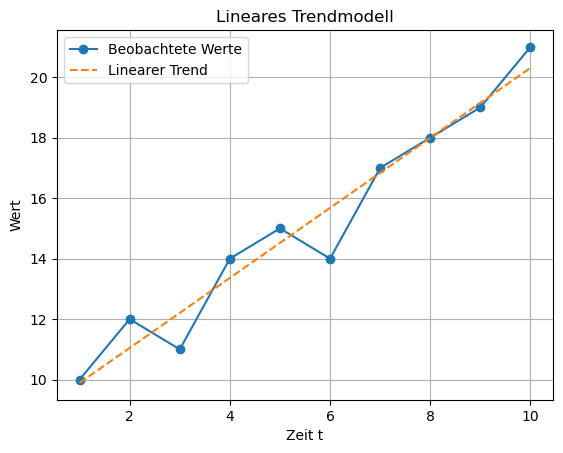

Geschätztes Trendmodell: m(t) = 8.73 + 1.16t


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Beispielhafte Zeitreihe
t = np.arange(1, 11)
x = np.array([10, 12, 11, 14, 15, 14, 17, 18, 19, 21])

# Lineares Trendmodell schätzen
a1, a0 = np.polyfit(t, x, 1)
trend = a0 + a1 * t

# Zeitreihe und Trend darstellen
plt.plot(t, x, "o-", label="Beobachtete Werte")
plt.plot(t, trend, "--", label="Linearer Trend")
plt.xlabel("Zeit t")
plt.ylabel("Wert")
plt.title("Lineares Trendmodell")
plt.legend()
plt.grid(True)
plt.show()

print(f"Geschätztes Trendmodell: m(t) = {a0:.2f} + {a1:.2f}t")


## Gleitende Durchschnitte

Ein gleitender Durchschnitt wird zur Trendschätzung einer Zeitreihe $X_t$ verwendet. Dabei werden Beobachtungen mit bestimmten Gewichten kombiniert, um kurzfristige Schwankungen zu glätten. Die allgemeine Formel lautet:

$$
\hat{m}(t)=\sum_{j=-q}^{q} w_j X_{t+j}
$$

Dabei bezeichnet:

- $X_t$: Beobachtung zum Zeitpunkt \(t\)
- $ \hat{m}(t)$: geschätzter Trend zum Zeitpunkt \(t\)
- $w_j$: Gewicht der Beobachtung \(X_{t+j}\)
- $q$: Anzahl der berücksichtigten Beobachtungen auf jeder Seite

Die Gewichte erfüllen die Bedingung: $\sum_{j=-q}^{q} w_j=1$. Dadurch bleibt eine konstante Zeitreihe bei der Glättung unverändert.

### Symmetrischer gleitender Durchschnitt
Ein gleitendes Mittel heißt symmetrisch, wenn für die Gewichte gilt:

$$
w_j=w_{-j}, \qquad j=1,\ldots,q
$$

Die Gewichte der Beobachtungen vor und nach dem Zeitpunkt $t$ sind also gleich. Eine typische Wahl der Gewichte ist:

$$
w_j=\frac{1}{2q+1},
\qquad j=-q,\ldots,q
$$

Damit ergibt sich der einfache symmetrische gleitende Durchschnitt:

$$
\hat{m}(t)=
\frac{1}{2q+1}
\sum_{j=-q}^{q}X_{t+j}
$$



,Original,Symmetrischer Durchschnitt
1,10,NaN
2,14,12.000000
3,12,14.666667
4,18,15.333333
5,16,18.000000
6,20,19.333333
7,22,NaN


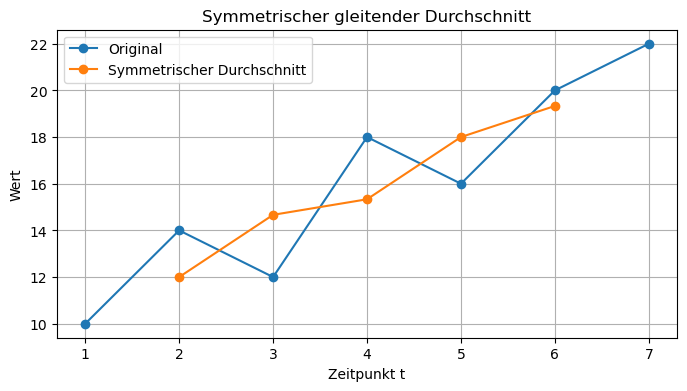

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Beispielzeitreihe
x = pd.Series(
    [10, 14, 12, 18, 16, 20, 22],
    index=range(1, 8),
    name="X_t"
)

# Fensterlänge: 2q + 1 = 3, also q = 1
q = 1
fenster = 2 * q + 1

# Symmetrischer gleitender Durchschnitt
sma_symmetrisch = x.rolling(
    window=fenster,
    center=True
).mean()

display(pd.DataFrame({
    "Original": x,
    "Symmetrischer Durchschnitt": sma_symmetrisch
}))

# Visualisierung
plt.figure(figsize=(8, 4))
plt.plot(x.index, x, marker="o", label="Original")
plt.plot(
    x.index,
    sma_symmetrisch,
    marker="o",
    label="Symmetrischer Durchschnitt"
)
plt.xlabel("Zeitpunkt t")
plt.ylabel("Wert")
plt.title("Symmetrischer gleitender Durchschnitt")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
### Einseitiger gleitender Durchschnitt